# Project 11: Handwritten Digit Classification Using CNN

## Objective
Build a Convolutional Neural Network (CNN) to classify handwritten digits from the MNIST dataset.

### Tasks
1. Load and preprocess the MNIST handwritten digit dataset.
2. Build and train a basic CNN with convolutional, pooling, and classification layers.
3. Evaluate the model with test accuracy, a confusion matrix, a classification report, and sample predictions.

### Expected Result
Train a CNN to classify digits 0–9. The confusion matrix highlights commonly confused digits, while the classification report gives precision, recall, and F1-score for each class.

## 1. Import Libraries and Select Device

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.0+cpu
CUDA available: False
Device: cpu


## 2. Load and Preprocess MNIST

MNIST contains 28 × 28 grayscale images of handwritten digits. Images are converted to tensors and normalized using the standard MNIST mean and standard deviation to support stable training.

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST("./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST("./data", train=False, download=True, transform=transform)

batch_size = 128
train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True,
    num_workers=0, pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    test_dataset, batch_size=batch_size, shuffle=False,
    num_workers=0, pin_memory=torch.cuda.is_available()
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Image tensor shape:", train_dataset[0][0].shape)

100%|██████████| 9.91M/9.91M [01:17<00:00, 128kB/s] 
100%|██████████| 28.9k/28.9k [00:00<00:00, 125kB/s]
100%|██████████| 1.65M/1.65M [00:21<00:00, 76.3kB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.54MB/s]

Training images: 60000
Testing images: 10000
Image tensor shape: torch.Size([1, 28, 28])


## Sample Images

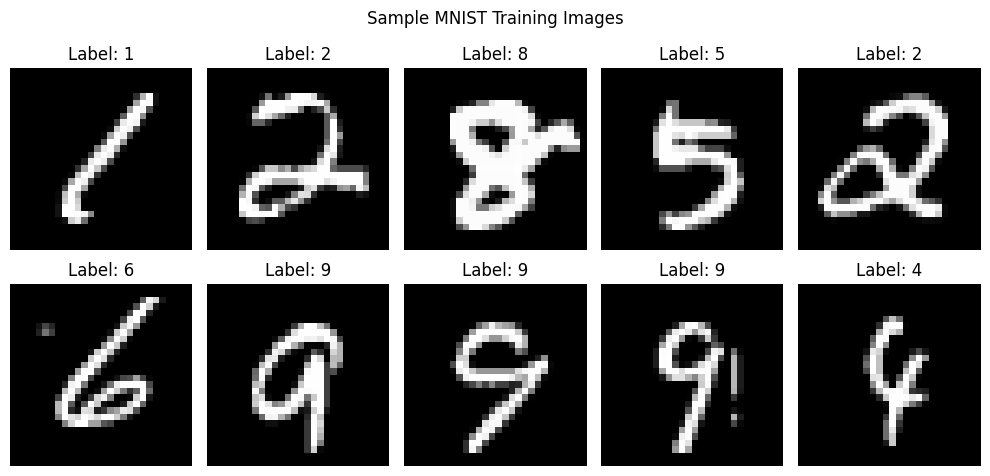

In [3]:
images, labels = next(iter(train_loader))
mean, std = 0.1307, 0.3081
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for ax, image, label in zip(axes.ravel(), images[:10], labels[:10]):
    display_image = image.squeeze().numpy() * std + mean
    ax.imshow(display_image, cmap="gray")
    ax.set_title(f"Label: {label.item()}")
    ax.axis("off")
plt.suptitle("Sample MNIST Training Images")
plt.tight_layout()
plt.show()

## 3. Build the CNN

The network uses two convolutional layers to learn visual features, max-pooling to reduce spatial dimensions, dropout to help reduce overfitting, and fully connected layers to classify an image into one of ten digits.

In [4]:
class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),                 # 28x28 -> 14x14
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)                  # 14x14 -> 7x7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, 10)              # logits for digits 0-9
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = DigitCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
print(model)

DigitCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


## 4. Train the CNN

Train for five epochs. Each batch performs a forward pass, calculates cross-entropy loss, backpropagates gradients, and updates model parameters.

In [5]:
num_epochs = 5
train_losses = []
train_accuracies = []

for epoch in range(1, num_epochs + 1):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for batch_images, batch_labels in train_loader:
        batch_images = batch_images.to(device, non_blocking=True)
        batch_labels = batch_labels.to(device, non_blocking=True)
        optimizer.zero_grad()
        outputs = model(batch_images)
        loss = criterion(outputs, batch_labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_images.size(0)
        correct += (outputs.argmax(dim=1) == batch_labels).sum().item()
        total += batch_labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_acc)
    print(f"Epoch {epoch}/{num_epochs} | Loss: {epoch_loss:.4f} | Training accuracy: {epoch_acc:.4f}")

Epoch 1/5 | Loss: 0.2056 | Training accuracy: 0.9364
Epoch 2/5 | Loss: 0.0596 | Training accuracy: 0.9819
Epoch 3/5 | Loss: 0.0427 | Training accuracy: 0.9866
Epoch 4/5 | Loss: 0.0332 | Training accuracy: 0.9895
Epoch 5/5 | Loss: 0.0274 | Training accuracy: 0.9911


## 5. Plot Training Loss and Accuracy

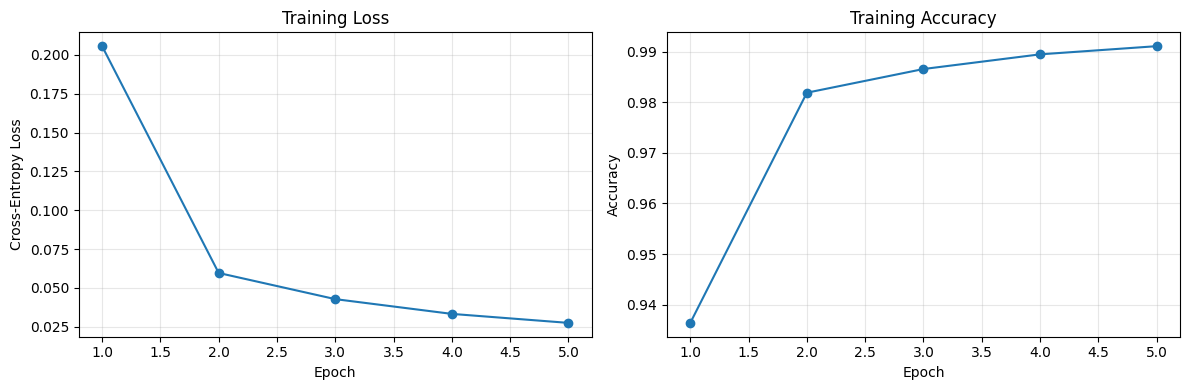

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, num_epochs + 1), train_losses, marker="o")
axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].grid(alpha=0.3)

axes[1].plot(range(1, num_epochs + 1), train_accuracies, marker="o")
axes[1].set_title("Training Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Evaluate on the Test Set

The test set was not used to update the model. Its accuracy indicates how well the CNN generalizes to unseen handwritten digits.

In [7]:
model.eval()
all_labels = []
all_predictions = []

with torch.no_grad():
    for batch_images, batch_labels in test_loader:
        batch_images = batch_images.to(device, non_blocking=True)
        outputs = model(batch_images)
        predictions = outputs.argmax(dim=1).cpu().numpy()
        all_predictions.extend(predictions)
        all_labels.extend(batch_labels.numpy())

test_accuracy = accuracy_score(all_labels, all_predictions)
print(f"Test accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")

Test accuracy: 0.9919 (99.19%)


## 7. Confusion Matrix

Values on the diagonal are correctly classified examples. Off-diagonal values indicate which true digits are predicted as other digits.

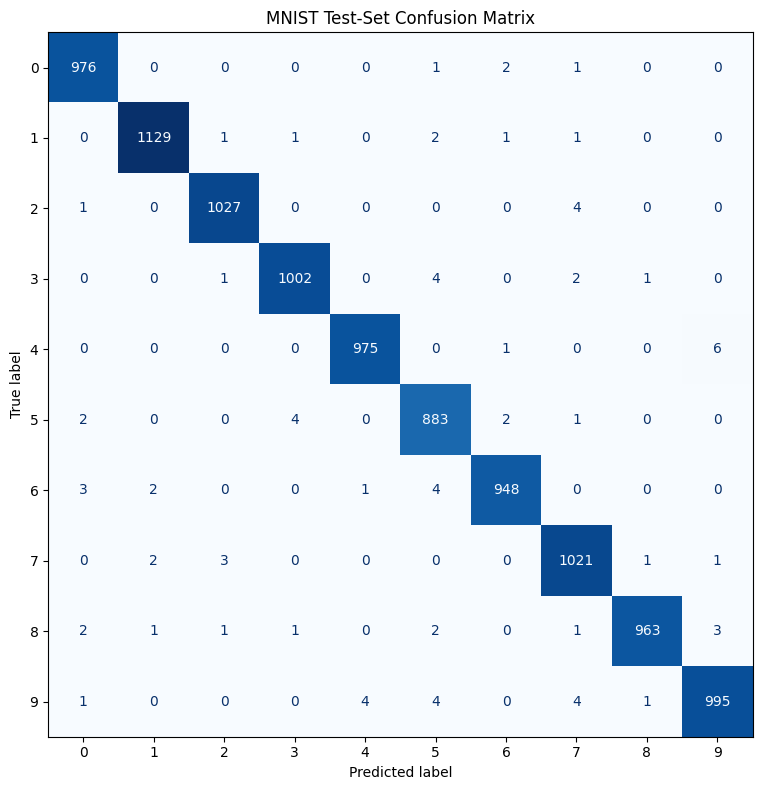

Most common misclassifications (true -> predicted):
4 -> 9: 6 images
2 -> 7: 4 images
3 -> 5: 4 images
5 -> 3: 4 images
6 -> 5: 4 images
9 -> 4: 4 images
7 -> 2: 3 images
8 -> 9: 3 images
0 -> 6: 2 images
1 -> 5: 2 images


In [8]:
cm = confusion_matrix(all_labels, all_predictions, labels=list(range(10)))
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(range(10))
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
plt.title("MNIST Test-Set Confusion Matrix")
plt.tight_layout()
plt.show()

cm_off_diagonal = cm.copy()
np.fill_diagonal(cm_off_diagonal, 0)
misclassifications = []
for true_digit in range(10):
    predicted_digit = int(np.argmax(cm_off_diagonal[true_digit]))
    count = int(cm_off_diagonal[true_digit, predicted_digit])
    if count > 0:
        misclassifications.append((true_digit, predicted_digit, count))

misclassifications.sort(key=lambda item: item[2], reverse=True)
print("Most common misclassifications (true -> predicted):")
for true_digit, predicted_digit, count in misclassifications[:10]:
    print(f"{true_digit} -> {predicted_digit}: {count} images")

## 8. Classification Report

The classification report shows precision, recall, and F1-score for each digit, as well as the number of test examples (support).

In [9]:
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(10)),
    target_names=[str(i) for i in range(10)],
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

           0     0.9909    0.9959    0.9934       980
           1     0.9956    0.9947    0.9952      1135
           2     0.9942    0.9952    0.9947      1032
           3     0.9940    0.9921    0.9931      1010
           4     0.9949    0.9929    0.9939       982
           5     0.9811    0.9899    0.9855       892
           6     0.9937    0.9896    0.9916       958
           7     0.9865    0.9932    0.9898      1028
           8     0.9969    0.9887    0.9928       974
           9     0.9900    0.9861    0.9881      1009

    accuracy                         0.9919     10000
   macro avg     0.9918    0.9918    0.9918     10000
weighted avg     0.9919    0.9919    0.9919     10000



## 9. Sample Predictions

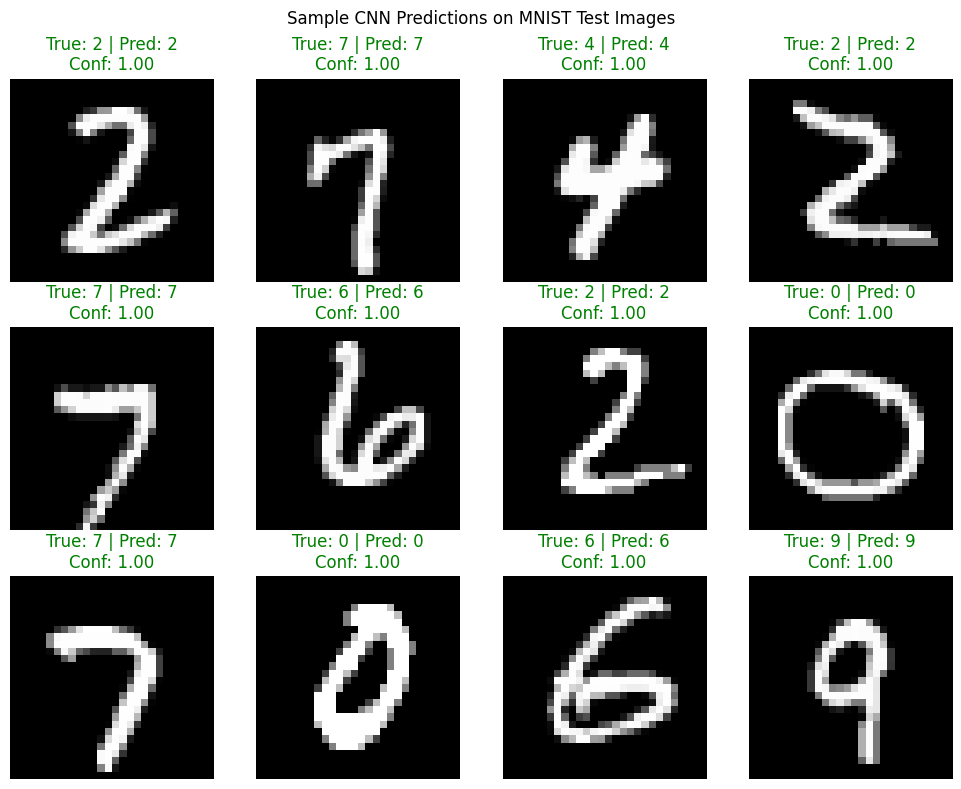

In [10]:
rng = np.random.default_rng(SEED)
sample_indices = rng.choice(len(test_dataset), size=12, replace=False)
fig, axes = plt.subplots(3, 4, figsize=(10, 8))
model.eval()

for ax, idx in zip(axes.ravel(), sample_indices):
    image, true_label = test_dataset[int(idx)]
    with torch.no_grad():
        logits = model(image.unsqueeze(0).to(device))
        probabilities = torch.softmax(logits, dim=1)
        predicted_label = int(logits.argmax(dim=1).item())
        confidence = float(probabilities.max().item())

    display_image = image.squeeze().numpy() * std + mean
    ax.imshow(display_image, cmap="gray")
    color = "green" if predicted_label == true_label else "red"
    ax.set_title(
        f"True: {true_label} | Pred: {predicted_label}\nConf: {confidence:.2f}",
        color=color
    )
    ax.axis("off")

plt.suptitle("Sample CNN Predictions on MNIST Test Images")
plt.tight_layout()
plt.show()

## 10. Save the Trained Model

In [11]:
model_path = "mnist_digit_cnn.pth"
torch.save({
    "model_state_dict": model.state_dict(),
    "test_accuracy": test_accuracy,
    "class_names": list(range(10))
}, model_path)
print("Trained model saved to:", os.path.abspath(model_path))

Trained model saved to: c:\Users\vishe\OneDrive\Documents\D_Drive\Notes\Sem_5\Deep Learning\mnist_digit_cnn.pth


## 11. Conclusion

This project trained a CNN to classify MNIST handwritten digits. Convolution and pooling layers learn useful image features, while the fully connected layers map those features to one of ten classes.

Test accuracy summarizes overall performance. The confusion matrix identifies which digits are frequently confused, and the classification report provides class-wise precision, recall, and F1-score. Sample predictions offer a visual check of correct and incorrect classifications.

The trained model is saved as `mnist_digit_cnn.pth` for future inference.